<a href="https://colab.research.google.com/github/ronan-cunha/machine-learning-course/blob/main/Notebooks/aula_13_interpretable_machine_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_openml, load_diabetes
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

In [ ]:
# ==============================================================================
# ETAPA 1: Carregar Dataset Real (Diabetes)
# ==============================================================================
# O dataset possui 442 observações e 10 variáveis preditoras clínicas:
# age (idade), sex (sexo), bmi (IMC), bp (pressão arterial média)
# s1 a s6 (seis medições do soro sanguíneo, ex: colesterol total, LDL, HDL, triglicérides, glicose)
# https://scikit-learn.org/stable/datasets/toy_dataset.html#diabetes-dataset
diabetes = load_diabetes(as_frame=True)
df = diabetes.frame
df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [ ]:
# ==============================================================================
# ETAPA 2: Divisão entre Treino e Teste
# ==============================================================================
X = df.drop(columns=["target"])
y = df["target"]

feature_names = X.columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Amostras de Treino: {X_train.shape[0]} | Amostras de Teste: {X_test.shape[0]}\n")

Amostras de Treino: 353 | Amostras de Teste: 89



In [ ]:
# ==============================================================================
# ETAPA 3: Instanciar e Treinar o Modelo Random Forest
# ==============================================================================
rf_model = RandomForestRegressor(
    n_estimators=100,
    criterion = 'squared_error', #absolute_error
    max_features = 5,
    min_samples_leaf=2,
    oob_score=True,
    random_state=42,
    n_jobs=-1,
)
rf_model = rf_model.fit(X_train, y_train)

In [ ]:
# ==============================================================================
# ETAPA 5: Importância das Variáveis (MDI)
# ==============================================================================
df_importance = pd.DataFrame(
    {"Feature": feature_names, "Importancia": rf_model.feature_importances_}
).sort_values(by="Importancia", ascending=False)

print("--- Importância das Variáveis no Dataset Diabetes (MDI) ---")
print(df_importance.to_string(index=False), "\n")

--- Importância das Variáveis no Dataset Diabetes (MDI) ---
Feature  Importancia
    bmi     0.305160
     s5     0.216052
     bp     0.108293
     s6     0.074387
     s3     0.068948
     s4     0.058805
     s2     0.054684
    age     0.051449
     s1     0.050978
    sex     0.011242 



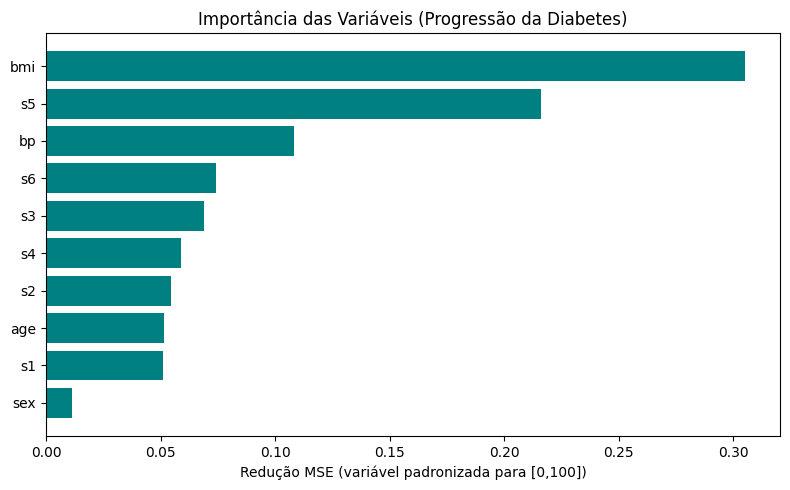

In [ ]:
# ==============================================================================
# ETAPA 6: Visualização Gráfica
# ==============================================================================
fig, ax = plt.subplots(1, 1, figsize=(8, 5))

# Gráfico 1: Importância das Variáveis
ax.barh(
    df_importance["Feature"], df_importance["Importancia"], color="teal"
)
ax.invert_yaxis()
ax.set_title("Importância das Variáveis (Progressão da Diabetes)")
ax.set_xlabel("Redução MSE (variável padronizada para [0,100])")

plt.tight_layout()
plt.show()

# Shap value
https://shap.readthedocs.io/en/latest/index.html


In [ ]:
import shap

explainer = shap.TreeExplainer(rf_model)
shap_values = explainer(X_test)

### Análise Global: Importância e Impacto das Variáveis
O gráfico abaixo (Beeswarm Plot) mostra o impacto de cada variável na previsão do modelo para todo o conjunto de teste. Variáveis no topo são as mais importantes.

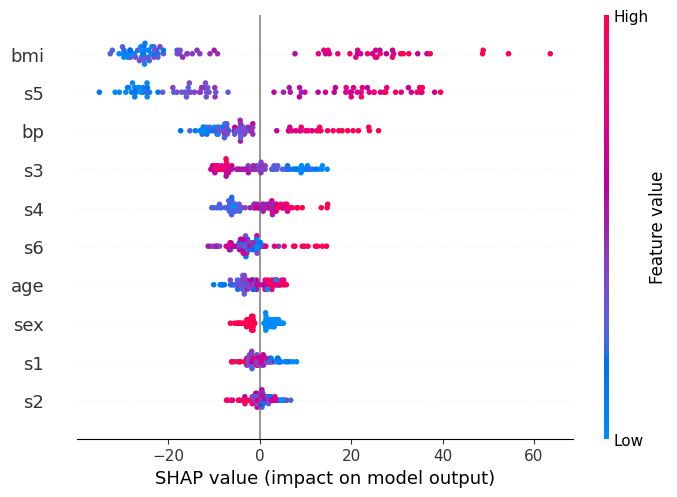

In [ ]:
plt.figure(figsize=(10, 6))
shap.plots.beeswarm(shap_values)
plt.show()

### Análise Local: Explicação de uma Única Previsão
Vamos visualizar como as variáveis contribuíram para a previsão da primeira amostra do conjunto de teste (índice 0) usando um gráfico de cascata (Waterfall Plot).

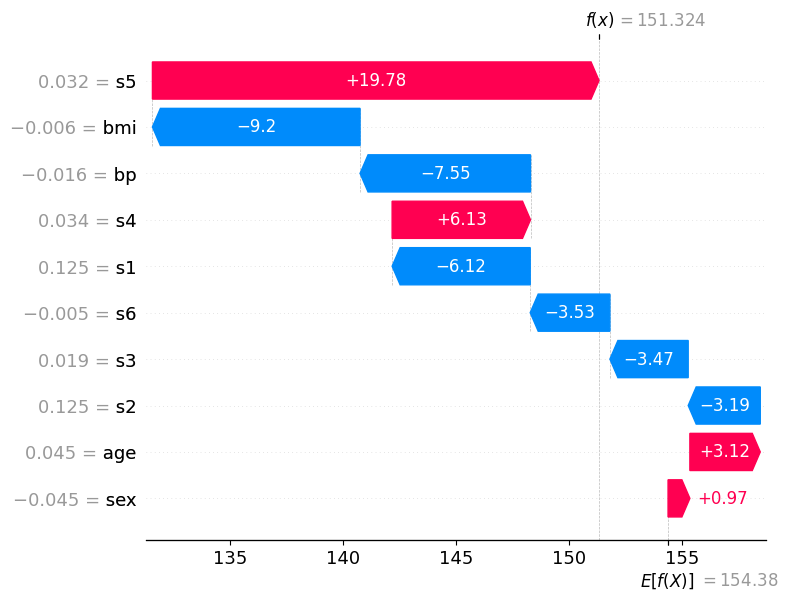

In [ ]:
plt.figure(figsize=(10, 6))
# Exibe a contribuição de cada feature para a primeira linha do conjunto de teste
shap.plots.waterfall(shap_values[0])
plt.show()